In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load monthly EV registration data
df = pd.read_csv('/content/EV_Monthly_Registrations.csv')

# Display first five records
df.head()

,month,registration_year,registration_month,ev_registrations,mom_growth_percent
0,2025-01-01,2025,January,177181,NaN
1,2025-02-01,2025,February,145284,-18.00
2,2025-03-01,2025,March,213700,47.09
3,2025-04-01,2025,April,174907,-18.15
4,2025-05-01,2025,May,186909,6.86


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (22, 5)

Column Names:
['month', 'registration_year', 'registration_month', 'ev_registrations', 'mom_growth_percent']

Data Types:
month                  object
registration_year       int64
registration_month     object
ev_registrations        int64
mom_growth_percent    float64
dtype: object

Missing Values:
month                 0
registration_year     0
registration_month    0
ev_registrations      0
mom_growth_percent    1
dtype: int64


In [ ]:
# Convert month column into datetime
df['month'] = pd.to_datetime(df['month'])

# Sort data chronologically
df = df.sort_values('month').reset_index(drop=True)

# Check date range
print("Start Date:", df['month'].min())
print("End Date:", df['month'].max())

# Check monthly registration data
display(df.head(5))

# Check last five records
display(df.tail(5))

# Check duplicate months
print("Duplicate Months:", df['month'].duplicated().sum())

# Check monthly frequency
print("Total Monthly Records:", len(df))

Start Date: 2025-01-01 00:00:00
End Date: 2026-10-01 00:00:00


,month,registration_year,registration_month,ev_registrations,mom_growth_percent
0,2025-01-01,2025,January,177181,NaN
1,2025-02-01,2025,February,145284,-18.00
2,2025-03-01,2025,March,213700,47.09
3,2025-04-01,2025,April,174907,-18.15
4,2025-05-01,2025,May,186909,6.86


,month,registration_year,registration_month,ev_registrations,mom_growth_percent
17,2026-06-01,2026,June,310747,12.32
18,2026-07-01,2026,July,332812,7.10
19,2026-08-01,2026,August,303279,-8.87
20,2026-09-01,2026,September,337844,11.40
21,2026-10-01,2026,October,319871,-5.32


Duplicate Months: 0
Total Monthly Records: 22


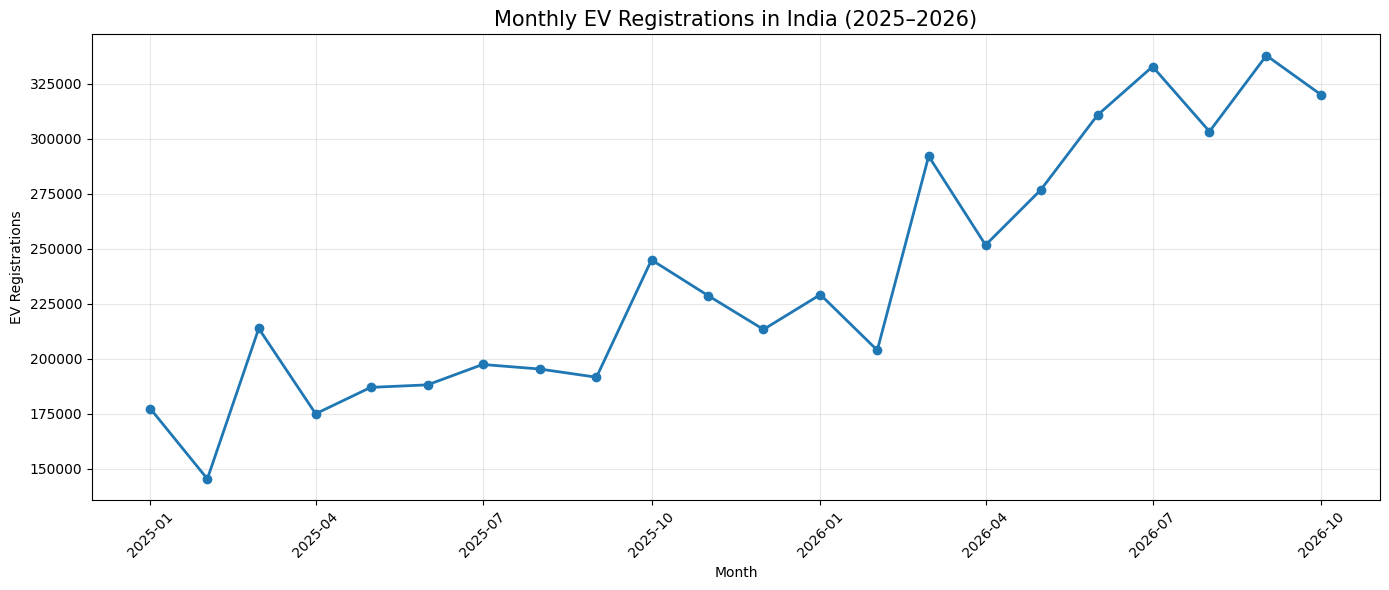

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df['month'],
    df['ev_registrations'],
    marker='o',
    linewidth=2
)

plt.title(
    'Monthly EV Registrations in India (2025–2026)',
    fontsize=15
)

plt.xlabel('Month')
plt.ylabel('EV Registrations')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

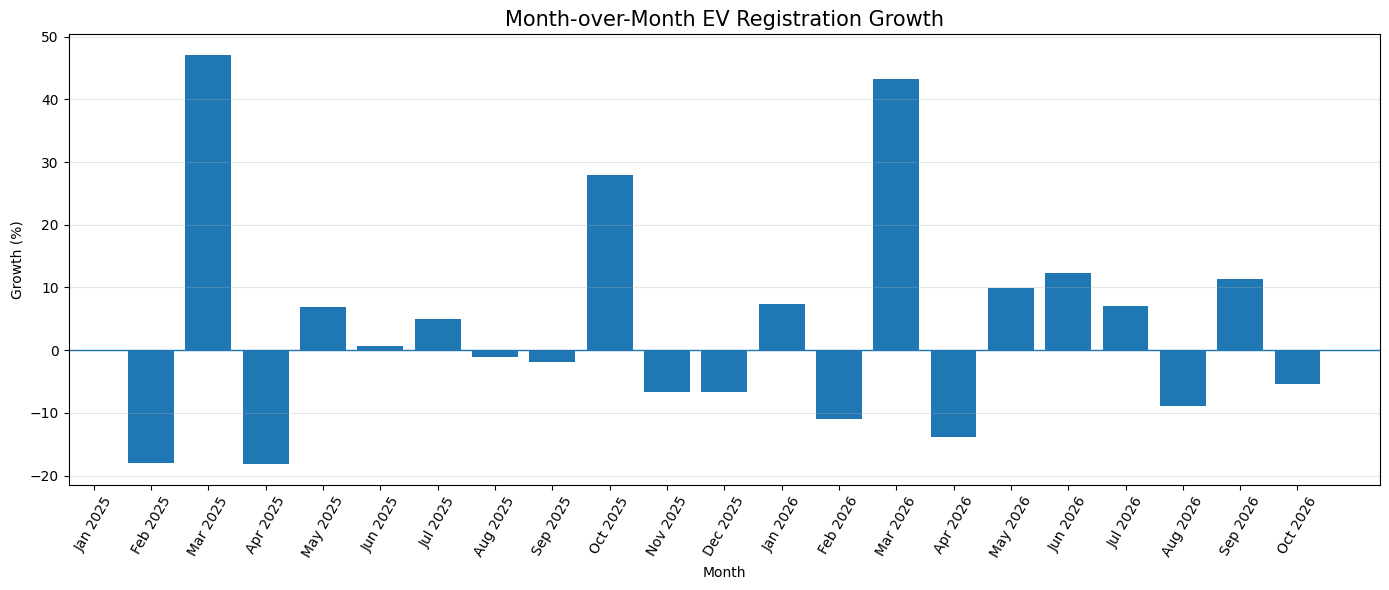

In [ ]:
plt.figure(figsize=(14, 6))

plt.bar(
    df['month'].dt.strftime('%b %Y'),
    df['mom_growth_percent']
)

plt.title(
    'Month-over-Month EV Registration Growth',
    fontsize=15
)

plt.xlabel('Month')
plt.ylabel('Growth (%)')

plt.xticks(rotation=60)
plt.axhline(y=0, linewidth=1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("EV Registration Statistical Summary")

display(
    df['ev_registrations'].describe().to_frame()
)

print("\nHighest Monthly Registrations:")
display(
    df.loc[
        df['ev_registrations'].idxmax(),
        ['month', 'ev_registrations']
    ]
)

print("\nLowest Monthly Registrations:")
display(
    df.loc[
        df['ev_registrations'].idxmin(),
        ['month', 'ev_registrations']
    ]
)

print("\nAverage Monthly Registrations:")
print(round(df['ev_registrations'].mean(), 2))

print("\nMedian Monthly Registrations:")
print(df['ev_registrations'].median())

EV Registration Statistical Summary


,ev_registrations
count,22.000000
mean,237031.500000
std,57488.746735
min,145284.000000
25%,192466.750000
50%,221129.000000
75%,288203.250000
max,337844.000000



Highest Monthly Registrations:


,20
month,2026-09-01 00:00:00
ev_registrations,337844



Lowest Monthly Registrations:


,1
month,2025-02-01 00:00:00
ev_registrations,145284



Average Monthly Registrations:
237031.5

Median Monthly Registrations:
221129.0


In [ ]:
# Create a copy to preserve the original dataset
model_df = df.copy()

# Calendar features
model_df['month_number'] = model_df['month'].dt.month
model_df['quarter'] = model_df['month'].dt.quarter

# Lag features
model_df['lag_1'] = model_df['ev_registrations'].shift(1)
model_df['lag_2'] = model_df['ev_registrations'].shift(2)
model_df['lag_3'] = model_df['ev_registrations'].shift(3)

# Previous 3-month rolling average
model_df['rolling_mean_3'] = (
    model_df['ev_registrations']
    .shift(1)
    .rolling(window=3)
    .mean()
)

# Display engineered dataset
display(model_df.head(10))

print("Original rows:", len(df))
print("Rows after feature engineering:", len(model_df))

print("\nMissing values in engineered features:")
print(model_df.isnull().sum())

,month,registration_year,registration_month,ev_registrations,mom_growth_percent,month_number,quarter,lag_1,lag_2,lag_3,rolling_mean_3
0,2025-01-01,2025,January,177181,NaN,1,1,NaN,NaN,NaN,NaN
1,2025-02-01,2025,February,145284,-18.00,2,1,177181.0,NaN,NaN,NaN
2,2025-03-01,2025,March,213700,47.09,3,1,145284.0,177181.0,NaN,NaN
3,2025-04-01,2025,April,174907,-18.15,4,2,213700.0,145284.0,177181.0,178721.666667
4,2025-05-01,2025,May,186909,6.86,5,2,174907.0,213700.0,145284.0,177963.666667
5,2025-06-01,2025,June,188063,0.62,6,2,186909.0,174907.0,213700.0,191838.666667
6,2025-07-01,2025,July,197330,4.93,7,3,188063.0,186909.0,174907.0,183293.000000
7,2025-08-01,2025,August,195268,-1.04,8,3,197330.0,188063.0,186909.0,190767.333333
8,2025-09-01,2025,September,191533,-1.91,9,3,195268.0,197330.0,188063.0,193553.666667
9,2025-10-01,2025,October,244888,27.86,10,4,191533.0,195268.0,197330.0,194710.333333


Original rows: 22
Rows after feature engineering: 22

Missing values in engineered features:
month                 0
registration_year     0
registration_month    0
ev_registrations      0
mom_growth_percent    1
month_number          0
quarter               0
lag_1                 1
lag_2                 2
lag_3                 3
rolling_mean_3        3
dtype: int64


In [ ]:
# Remove rows with missing engineered features
model_data = model_df.dropna(
    subset=[
        'lag_1',
        'lag_2',
        'lag_3',
        'rolling_mean_3'
    ]
).copy()

# Reset index
model_data.reset_index(drop=True, inplace=True)

print("Original dataset:", len(model_df))
print("Modelling dataset:", len(model_data))

print("\nRemaining missing values:")
print(model_data.isnull().sum())

print("\nModelling dataset preview:")
display(model_data.head())

Original dataset: 22
Modelling dataset: 19

Remaining missing values:
month                 0
registration_year     0
registration_month    0
ev_registrations      0
mom_growth_percent    0
month_number          0
quarter               0
lag_1                 0
lag_2                 0
lag_3                 0
rolling_mean_3        0
dtype: int64

Modelling dataset preview:


,month,registration_year,registration_month,ev_registrations,mom_growth_percent,month_number,quarter,lag_1,lag_2,lag_3,rolling_mean_3
0,2025-04-01,2025,April,174907,-18.15,4,2,213700.0,145284.0,177181.0,178721.666667
1,2025-05-01,2025,May,186909,6.86,5,2,174907.0,213700.0,145284.0,177963.666667
2,2025-06-01,2025,June,188063,0.62,6,2,186909.0,174907.0,213700.0,191838.666667
3,2025-07-01,2025,July,197330,4.93,7,3,188063.0,186909.0,174907.0,183293.000000
4,2025-08-01,2025,August,195268,-1.04,8,3,197330.0,188063.0,186909.0,190767.333333


In [ ]:
# Define target and features
features = [
    'month_number',
    'quarter',
    'lag_1',
    'lag_2',
    'lag_3',
    'rolling_mean_3'
]

X = model_data[features]
y = model_data['ev_registrations']

# Chronological 80:20 split
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display split information
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining period:")
print(model_data['month'].iloc[0], "to",
      model_data['month'].iloc[split_index - 1])

print("\nTesting period:")
print(model_data['month'].iloc[split_index], "to",
      model_data['month'].iloc[-1])

Training observations: 15
Testing observations: 4

Training period:
2025-04-01 00:00:00 to 2026-06-01 00:00:00

Testing period:
2026-07-01 00:00:00 to 2026-10-01 00:00:00


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Initialize model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Predict test observations
lr_predictions = lr_model.predict(X_test)

# Evaluate model
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_mape = np.mean(
    np.abs((y_test.values - lr_predictions) / y_test.values)
) * 100

print("LINEAR REGRESSION MODEL RESULTS")
print("--------------------------------")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("MAPE:", round(lr_mape, 2), "%")

# Compare actual and predicted values
lr_results = pd.DataFrame({
    'Month': model_data['month'].iloc[split_index:].values,
    'Actual Registrations': y_test.values,
    'Predicted Registrations': np.round(lr_predictions).astype(int)
})

display(lr_results)

LINEAR REGRESSION MODEL RESULTS
--------------------------------
MAE: 35607.27
RMSE: 37050.64
MAPE: 11.1 %


,Month,Actual Registrations,Predicted Registrations
0,2026-07-01,332812,305973
1,2026-08-01,303279,340125
2,2026-09-01,337844,364711
3,2026-10-01,319871,371748


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

# Predict test observations
rf_predictions = rf_model.predict(X_test)

# Evaluate model
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_mape = np.mean(
    np.abs((y_test.values - rf_predictions) / y_test.values)
) * 100

print("RANDOM FOREST MODEL RESULTS")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("MAPE:", round(rf_mape, 2), "%")

# Compare actual and predicted values
rf_results = pd.DataFrame({
    'Month': model_data['month'].iloc[split_index:].values,
    'Actual Registrations': y_test.values,
    'Predicted Registrations': np.round(rf_predictions).astype(int)
})

display(rf_results)

RANDOM FOREST MODEL RESULTS
--------------------------------
MAE: 45958.69
RMSE: 47948.97
MAPE: 14.06 %


,Month,Actual Registrations,Predicted Registrations
0,2026-07-01,332812,278813
1,2026-08-01,303279,278813
2,2026-09-01,337844,277080
3,2026-10-01,319871,275265


In [ ]:
# Naive forecast: previous month's actual registrations
naive_predictions = model_data['lag_1'].iloc[split_index:].values

# Evaluation
naive_mae = mean_absolute_error(y_test, naive_predictions)

naive_rmse = np.sqrt(
    mean_squared_error(y_test, naive_predictions)
)

naive_mape = np.mean(
    np.abs(
        (y_test.values - naive_predictions) / y_test.values
    )
) * 100

print("NAIVE BASELINE RESULTS")
print("--------------------------------")
print("MAE:", round(naive_mae, 2))
print("RMSE:", round(naive_rmse, 2))
print("MAPE:", round(naive_mape, 2), "%")

naive_results = pd.DataFrame({
    'Month': model_data['month'].iloc[split_index:].values,
    'Actual Registrations': y_test.values,
    'Predicted Registrations': naive_predictions.astype(int)
})

display(naive_results)

NAIVE BASELINE RESULTS
--------------------------------
MAE: 26034.0
RMSE: 26818.05
MAPE: 8.05 %


,Month,Actual Registrations,Predicted Registrations
0,2026-07-01,332812,310747
1,2026-08-01,303279,332812
2,2026-09-01,337844,303279
3,2026-10-01,319871,337844


In [ ]:
comparison_df = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Naive Baseline'
    ],
    'MAE': [
        lr_mae,
        rf_mae,
        naive_mae
    ],
    'RMSE': [
        lr_rmse,
        rf_rmse,
        naive_rmse
    ],
    'MAPE': [
        lr_mape,
        rf_mape,
        naive_mape
    ]
})

comparison_df = comparison_df.sort_values(
    by='MAPE'
).reset_index(drop=True)

display(comparison_df.round(2))

,Model,MAE,RMSE,MAPE
0,Naive Baseline,26034.00,26818.05,8.05
1,Linear Regression,35607.27,37050.64,11.10
2,Random Forest,45958.69,47948.97,14.06


In [ ]:
best_model_name = comparison_df.loc[0, 'Model']

print("Best Performing Method:", best_model_name)
print("Best MAPE:", round(comparison_df.loc[0, 'MAPE'], 2), "%")

Best Performing Method: Naive Baseline
Best MAPE: 8.05 %


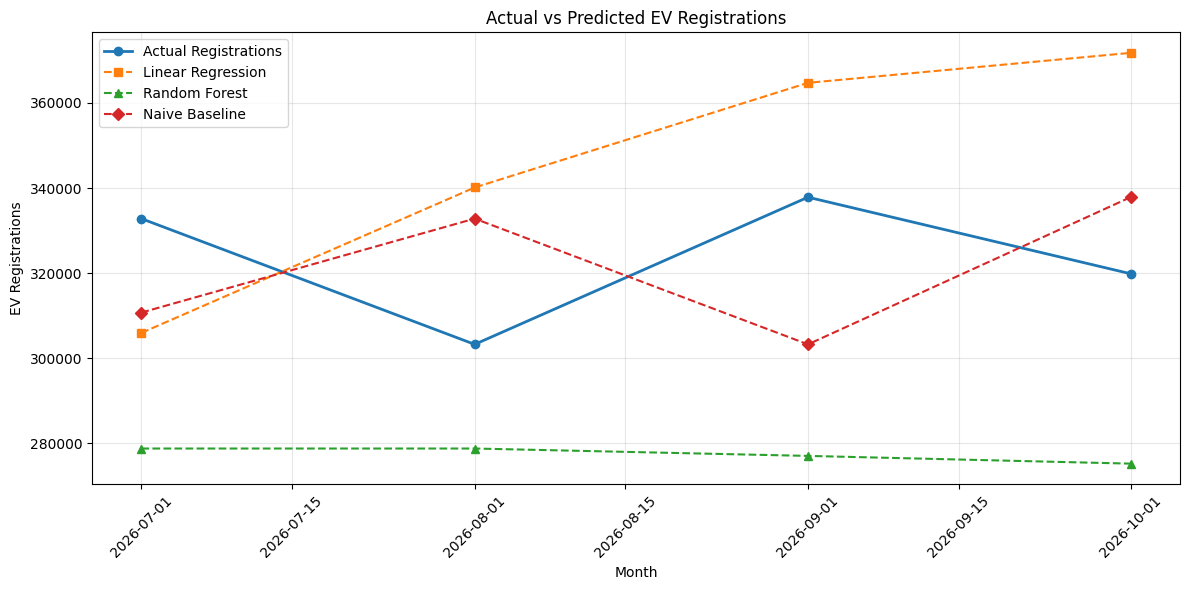

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    model_data['month'].iloc[split_index:],
    y_test.values,
    marker='o',
    linewidth=2,
    label='Actual Registrations'
)

plt.plot(
    model_data['month'].iloc[split_index:],
    lr_predictions,
    marker='s',
    linestyle='--',
    label='Linear Regression'
)

plt.plot(
    model_data['month'].iloc[split_index:],
    rf_predictions,
    marker='^',
    linestyle='--',
    label='Random Forest'
)

plt.plot(
    model_data['month'].iloc[split_index:],
    naive_predictions,
    marker='D',
    linestyle='--',
    label='Naive Baseline'
)

plt.title('Actual vs Predicted EV Registrations')
plt.xlabel('Month')
plt.ylabel('EV Registrations')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Six-month forecast using Naive Baseline

last_actual = df['ev_registrations'].iloc[-1]

future_dates = pd.date_range(
    start=df['month'].max() + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

forecast_df = pd.DataFrame({
    'Month': future_dates,
    'Predicted_EV_Registrations': [last_actual] * 6
})

display(forecast_df)

,Month,Predicted_EV_Registrations
0,2026-11-01,319871
1,2026-12-01,319871
2,2027-01-01,319871
3,2027-02-01,319871
4,2027-03-01,319871
5,2027-04-01,319871


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use training data only
train_series = y_train.reset_index(drop=True)

# Fit Holt's Linear Trend model
holt_model = ExponentialSmoothing(
    train_series,
    trend='add',
    damped_trend=True,
    seasonal=None
)

holt_fit = holt_model.fit(optimized=True)

# Forecast the 4 test months
holt_predictions = holt_fit.forecast(steps=len(y_test))

# Evaluate
holt_mae = mean_absolute_error(y_test, holt_predictions)
holt_rmse = np.sqrt(mean_squared_error(y_test, holt_predictions))
holt_mape = np.mean(
    np.abs((y_test.values - holt_predictions.values) / y_test.values)
) * 100

print("Holt's Linear Trend Results")
print("MAE:", round(holt_mae, 2))
print("RMSE:", round(holt_rmse, 2))
print("MAPE:", round(holt_mape, 2), "%")

Holt's Linear Trend Results
MAE: 29937.58
RMSE: 33737.49
MAPE: 9.09 %


In [ ]:
# Fixed-origin Naive Baseline
fixed_naive_predictions = np.repeat(
    y_train.iloc[-1],
    len(y_test)
)

# Evaluate fixed-origin Naive Baseline
fixed_naive_mae = mean_absolute_error(
    y_test, fixed_naive_predictions
)

fixed_naive_rmse = np.sqrt(
    mean_squared_error(y_test, fixed_naive_predictions)
)

fixed_naive_mape = np.mean(
    np.abs(
        (y_test.values - fixed_naive_predictions)
        / y_test.values
    )
) * 100

# Compare with Holt's method
fair_comparison = pd.DataFrame({
    'Model': ['Fixed-origin Naive Baseline', "Holt's Linear Trend"],
    'MAE': [fixed_naive_mae, holt_mae],
    'RMSE': [fixed_naive_rmse, holt_rmse],
    'MAPE': [fixed_naive_mape, holt_mape]
})

display(fair_comparison.round(2))

,Model,MAE,RMSE,MAPE
0,Fixed-origin Naive Baseline,16438.50,18439.97,4.99
1,Holt's Linear Trend,29937.58,33737.49,9.09


In [ ]:
# Create a separate dataset excluding October 2026
forecast_base_df = df[
    df['month'] < '2026-10-01'
].copy()

forecast_base_df = forecast_base_df.reset_index(drop=True)

# Check the dataset
print("Dataset Shape:", forecast_base_df.shape)
print("Start Month:", forecast_base_df['month'].min())
print("End Month:", forecast_base_df['month'].max())

display(forecast_base_df.tail())

Dataset Shape: (21, 5)
Start Month: 2025-01-01 00:00:00
End Month: 2026-09-01 00:00:00


,month,registration_year,registration_month,ev_registrations,mom_growth_percent
16,2026-05-01,2026,May,276663,9.94
17,2026-06-01,2026,June,310747,12.32
18,2026-07-01,2026,July,332812,7.10
19,2026-08-01,2026,August,303279,-8.87
20,2026-09-01,2026,September,337844,11.40


In [ ]:
# Create revised feature dataset
revised_model_df = forecast_base_df.copy()

revised_model_df['month_number'] = revised_model_df['month'].dt.month
revised_model_df['quarter'] = revised_model_df['month'].dt.quarter

revised_model_df['lag_1'] = revised_model_df['ev_registrations'].shift(1)
revised_model_df['lag_2'] = revised_model_df['ev_registrations'].shift(2)
revised_model_df['lag_3'] = revised_model_df['ev_registrations'].shift(3)

revised_model_df['rolling_mean_3'] = (
    revised_model_df['ev_registrations']
    .shift(1)
    .rolling(window=3)
    .mean()
)

display(revised_model_df.head(6))

,month,registration_year,registration_month,ev_registrations,mom_growth_percent,month_number,quarter,lag_1,lag_2,lag_3,rolling_mean_3
0,2025-01-01,2025,January,177181,NaN,1,1,NaN,NaN,NaN,NaN
1,2025-02-01,2025,February,145284,-18.00,2,1,177181.0,NaN,NaN,NaN
2,2025-03-01,2025,March,213700,47.09,3,1,145284.0,177181.0,NaN,NaN
3,2025-04-01,2025,April,174907,-18.15,4,2,213700.0,145284.0,177181.0,178721.666667
4,2025-05-01,2025,May,186909,6.86,5,2,174907.0,213700.0,145284.0,177963.666667
5,2025-06-01,2025,June,188063,0.62,6,2,186909.0,174907.0,213700.0,191838.666667


In [ ]:
# Remove rows with missing lag features
revised_model_data = revised_model_df.dropna(
    subset=['lag_1', 'lag_2', 'lag_3', 'rolling_mean_3']
).copy()

revised_model_data.reset_index(drop=True, inplace=True)

# Define features and target
features = [
    'month_number',
    'quarter',
    'lag_1',
    'lag_2',
    'lag_3',
    'rolling_mean_3'
]

X = revised_model_data[features]
y = revised_model_data['ev_registrations']

# Chronological 80/20 split
split_index = int(len(revised_model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Model Dataset:", revised_model_data.shape)
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

print("\nTraining Period:")
print(revised_model_data['month'].iloc[0], "to",
      revised_model_data['month'].iloc[split_index - 1])

print("\nTesting Period:")
print(revised_model_data['month'].iloc[split_index], "to",
      revised_model_data['month'].iloc[-1])

Model Dataset: (18, 11)
Training Rows: 14
Testing Rows: 4

Training Period:
2025-04-01 00:00:00 to 2026-05-01 00:00:00

Testing Period:
2026-06-01 00:00:00 to 2026-09-01 00:00:00


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np
import pandas as pd

# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

# 2. Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

# 3. Fixed-origin Naive Baseline
naive_predictions = np.repeat(
    y_train.iloc[-1],
    len(y_test)
)

# 4. Holt's Linear Trend
holt_model = ExponentialSmoothing(
    y_train.reset_index(drop=True),
    trend='add',
    damped_trend=True,
    seasonal=None
)

holt_fit = holt_model.fit(optimized=True)
holt_predictions = holt_fit.forecast(steps=len(y_test))

# Evaluation function
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual.values - np.array(predicted))
               / actual.values)
    ) * 100

    return round(mae, 2), round(rmse, 2), round(mape, 2)

# Comparison table
results = []

models = {
    'Linear Regression': lr_predictions,
    'Random Forest': rf_predictions,
    'Fixed-origin Naive Baseline': naive_predictions,
    "Holt's Linear Trend": holt_predictions
}

for name, predictions in models.items():
    mae, rmse, mape = evaluate_model(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

revised_comparison = pd.DataFrame(results)
revised_comparison = revised_comparison.sort_values(
    'MAPE'
).reset_index(drop=True)

display(revised_comparison)

,Model,MAE,RMSE,MAPE
0,Linear Regression,23079.80,24767.54,7.24
1,Holt's Linear Trend,42767.95,44807.03,13.18
2,Fixed-origin Naive Baseline,44507.50,46813.34,13.68
3,Random Forest,66765.90,68365.81,20.62


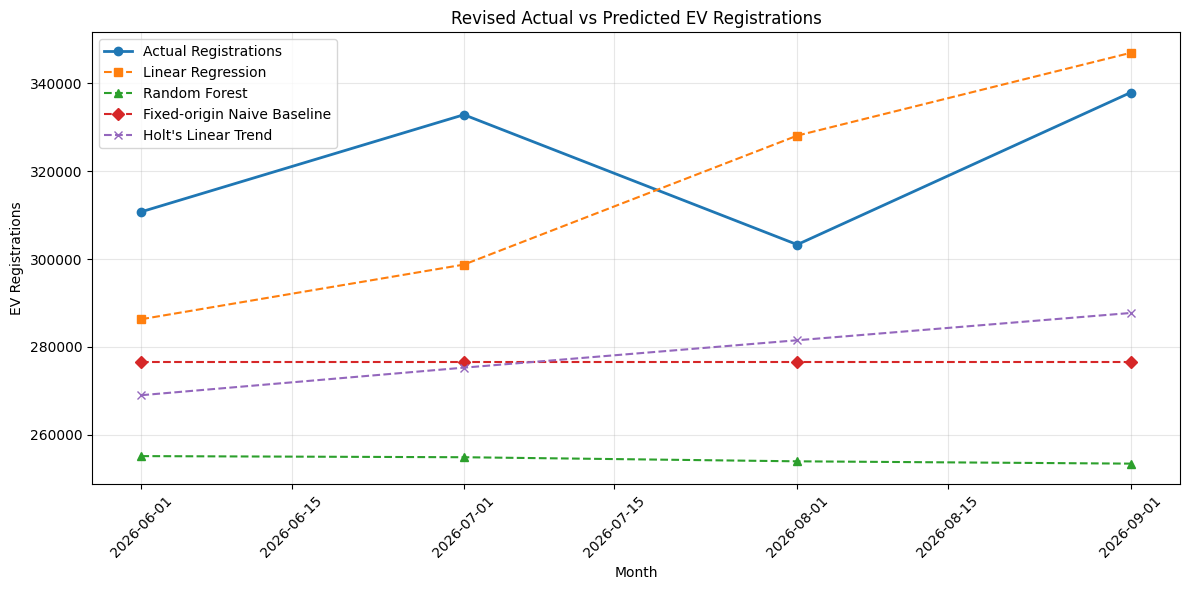

In [ ]:
plt.figure(figsize=(12, 6))

test_dates = revised_model_data['month'].iloc[split_index:]

plt.plot(
    test_dates, y_test.values,
    marker='o', linewidth=2,
    label='Actual Registrations'
)

plt.plot(
    test_dates, lr_predictions,
    marker='s', linestyle='--',
    label='Linear Regression'
)

plt.plot(
    test_dates, rf_predictions,
    marker='^', linestyle='--',
    label='Random Forest'
)

plt.plot(
    test_dates, naive_predictions,
    marker='D', linestyle='--',
    label='Fixed-origin Naive Baseline'
)

plt.plot(
    test_dates, holt_predictions,
    marker='x', linestyle='--',
    label="Holt's Linear Trend"
)

plt.title('Revised Actual vs Predicted EV Registrations')
plt.xlabel('Month')
plt.ylabel('EV Registrations')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Train final Linear Regression model on all available data

final_model = LinearRegression()
final_model.fit(X, y)

# Prepare historical registration values
history = revised_model_data['ev_registrations'].tolist()

# Generate next 6 months
future_dates = pd.date_range(
    start='2026-10-01',
    periods=6,
    freq='MS'
)

future_predictions = []

for date in future_dates:

    month_number = date.month
    quarter = date.quarter

    lag_1 = history[-1]
    lag_2 = history[-2]
    lag_3 = history[-3]
    rolling_mean_3 = np.mean(history[-3:])

    future_features = pd.DataFrame([{
        'month_number': month_number,
        'quarter': quarter,
        'lag_1': lag_1,
        'lag_2': lag_2,
        'lag_3': lag_3,
        'rolling_mean_3': rolling_mean_3
    }])

    prediction = final_model.predict(future_features)[0]

    prediction = max(0, round(prediction))

    future_predictions.append(prediction)
    history.append(prediction)

# Create forecast table
final_forecast_df = pd.DataFrame({
    'Month': future_dates,
    'Predicted_EV_Registrations': future_predictions
})

display(final_forecast_df)

,Month,Predicted_EV_Registrations
0,2026-10-01,358615
1,2026-11-01,361620
2,2026-12-01,383958
3,2027-01-01,402900
4,2027-02-01,414146
5,2027-03-01,431248


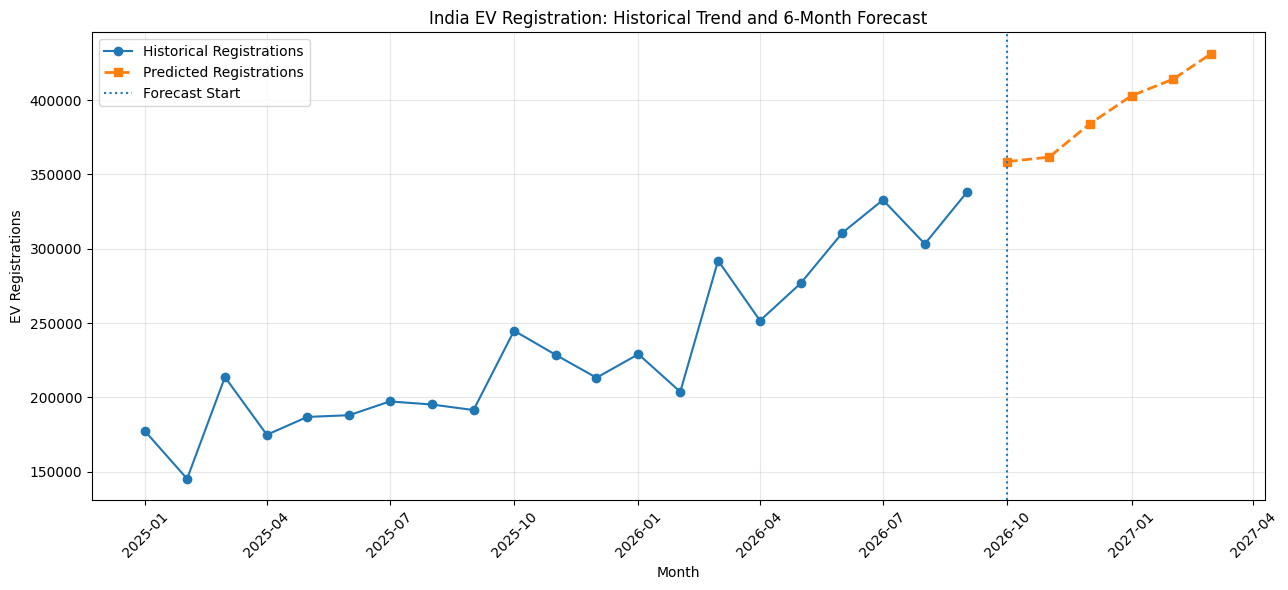

In [ ]:
plt.figure(figsize=(13, 6))

# Historical registrations
plt.plot(
    forecast_base_df['month'],
    forecast_base_df['ev_registrations'],
    marker='o',
    label='Historical Registrations'
)

# Future forecast
plt.plot(
    final_forecast_df['Month'],
    final_forecast_df['Predicted_EV_Registrations'],
    marker='s',
    linestyle='--',
    linewidth=2,
    label='Predicted Registrations'
)

# Forecast starting point
plt.axvline(
    x=pd.Timestamp('2026-10-01'),
    linestyle=':',
    label='Forecast Start'
)

plt.title('India EV Registration: Historical Trend and 6-Month Forecast')
plt.xlabel('Month')
plt.ylabel('EV Registrations')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
final_forecast_df.to_csv(
    'EV_Registration_6_Month_Forecast.csv',
    index=False
)

print("Forecast dataset exported successfully!")

Forecast dataset exported successfully!
